In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 20 - Regions: productivity vs labour use; and how robust is the growth regression?
Part 1 splits regional gaps in GDP per head into output per hour (productivity) and hours worked per inhabitant (labour utilisation: employment, hours, demography), for NUTS2 regions across the EU. Part 2 re-runs the cross-country growth regression with different horizons.

,GDP per head (EUR),GDP per hour (EUR),hours per inhabitant
area,,,
North-West,35491.7,45.4,777.7
North-East,36535.6,44.9,813.2
Centre,30507.6,40.3,755.9
South,20781.1,35.3,604.3
Islands,19846.0,34.6,574.3


South & Islands vs North, 2019: GDP per head 56% of North; of the log gap -0.58, productivity -0.24 (42%), hours per inhabitant -0.30 (51%)


,dispersion (sd of log GDP per head),share from productivity,share from hours per inhabitant
HU,0.40,0.18,0.82
RO,0.39,0.79,0.21
BG,0.36,0.70,0.30
CZ,0.36,0.57,0.43
BE,0.33,0.53,0.47
FR,0.30,0.34,0.66
IT,0.30,0.47,0.53
PL,0.27,0.67,0.33
DK,0.22,0.36,0.64
PT,0.22,0.28,0.72


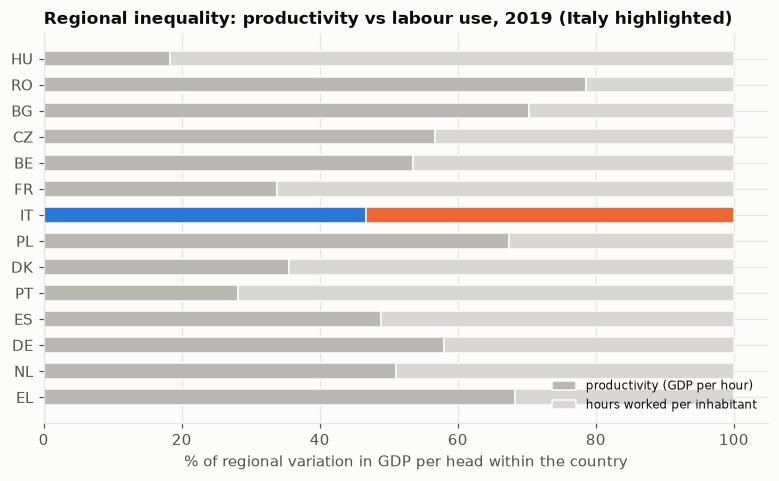

In [2]:
reg = load_regional()
def rw(ind): return reg[reg.indicator == ind].pivot(index="year", columns="geo", values="value")
gdp, hrs, pop = rw("nuts2_gdp_mio_eur"), rw("nuts2_hours_ths"), rw("nuts2_population")
def decomposition(year):
    cols = [c for c in gdp.columns if c in hrs.columns and c in pop.columns]
    d = pd.DataFrame({"y": gdp.loc[year, cols] * 1e6 / pop.loc[year, cols], "p": gdp.loc[year, cols] / hrs.loc[year, cols] * 1e3, "h": hrs.loc[year, cols] * 1e3 / pop.loc[year, cols]}).dropna()
    d["country"] = d.index.str[:2]; return d
Y = 2019; d = decomposition(Y); area = lambda g: {"ITC": "North-West", "ITH": "North-East", "ITI": "Centre", "ITF": "South", "ITG": "Islands"}.get(g[:3], "other")
it = d[d.country == "IT"].assign(area=lambda x: [area(g) for g in x.index]); order = ["North-West", "North-East", "Centre", "South", "Islands"]
tab = it.groupby("area")[["y", "p", "h"]].median().loc[order]; tab.columns = ["GDP per head (EUR)", "GDP per hour (EUR)", "hours per inhabitant"]
display(tab.round(1)); north = it[it.area.isin(["North-West", "North-East"])][["y", "p", "h"]].median(); south = it[it.area.isin(["South", "Islands"])][["y", "p", "h"]].median()
lr = np.log(south / north); print("South & Islands vs North, %d: GDP per head %.0f%% of North; of the log gap %.2f, productivity %.2f (%.0f%%), hours per inhabitant %.2f (%.0f%%)" % (Y, np.exp(lr.y) * 100, lr.y, lr.p, lr.p / lr.y * 100, lr.h, lr.h / lr.y * 100))
rows = {}
for c, g in d.groupby("country"):
    if len(g) < 5: continue
    ly, lp, lh = np.log(g.y), np.log(g.p), np.log(g.h); v = ly.var(); cov = np.cov(lp, lh)[0, 1]
    rows[c] = {"dispersion (sd of log GDP per head)": ly.std(), "share from productivity": (lp.var() + cov) / v, "share from hours per inhabitant": (lh.var() + cov) / v}
dec = pd.DataFrame(rows).T.sort_values("dispersion (sd of log GDP per head)", ascending=False); display(dec.round(2).head(12))
fig, ax = plt.subplots(figsize=(8.5, 4.6)); sel = dec.head(14).iloc[::-1]; yy = np.arange(len(sel))
ax.barh(yy, sel["share from productivity"] * 100, color=[ITALY_C if c == "IT" else PEER_C for c in sel.index], height=0.6, label="productivity (GDP per hour)", edgecolor=SURFACE)
ax.barh(yy, sel["share from hours per inhabitant"] * 100, left=sel["share from productivity"] * 100, color=[EU_C if c == "IT" else "#d8d7d2" for c in sel.index], height=0.6, label="hours worked per inhabitant", edgecolor=SURFACE)
ax.set_yticks(yy, sel.index); ax.set_xlabel("% of regional variation in GDP per head within the country"); ax.set_title(f"Regional inequality: productivity vs labour use, {Y} (Italy highlighted)"); ax.legend(fontsize=8, loc="lower right"); save(fig, "20_regional_decomposition")

In [3]:
# Regional panel with region and year fixed effects: log GDP per head on education, female employment and unemployment (NUTS2, 2013-2023)
from linearmodels.panel import PanelOLS
y = np.log(gdp * 1e6 / pop).stack().rename("ln_gdp_pc"); X = pd.concat({"tertiary": rw("nuts2_tertiary_attainment_25_64").stack(), "female_emp": rw("nuts2_employment_rate_20_64_female").stack(), "unemp": rw("nuts2_unemployment_rate").stack()}, axis=1)
df = pd.concat([y, X], axis=1).dropna().reset_index(); df.columns = ["year", "region", "ln_gdp_pc", "tertiary", "female_emp", "unemp"]; df = df[df.year.between(2013, 2023)]; df["country"] = df.region.str[:2]  # stacking a year x region table gives (year, region)
def fit(sub):
    p = sub.set_index(["region", "year"]); r = PanelOLS(p.ln_gdp_pc, p[["tertiary", "female_emp", "unemp"]], entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True)
    return pd.DataFrame({"coef": r.params, "p": r.pvalues}), int(r.nobs), r.rsquared_within
out = {}
for lab, sub in [("all EU27 regions", df), ("Italy", df[df.country == "IT"]), ("rest of EU27", df[df.country != "IT"])]:
    t, n, r2 = fit(sub); out[lab] = {"n": n, "within R2": round(r2, 3), **{f"{k} coef": round(t.loc[k, "coef"], 4) for k in t.index}, **{f"{k} p": round(t.loc[k, "p"], 3) for k in t.index}}
display(pd.DataFrame(out).T)

,n,within R2,tertiary coef,female_emp coef,unemp coef,tertiary p,female_emp p,unemp p
all EU27 regions,2542.0,0.170,-0.0052,0.0133,0.0058,0.042,0.000,0.012
Italy,231.0,0.077,-0.0020,0.0013,-0.0024,0.504,0.365,0.276
rest of EU27,2311.0,0.110,-0.0068,0.0128,0.0061,0.012,0.000,0.013


In [4]:
# Growth regression robustness: annual, 3-year and 5-year averages with country and time fixed effects
vars_ = {"gov_debt_pct_gdp": "debt/GDP", "gfcf_pct_gdp": "investment/GDP", "employment_rate_20_64": "employment rate", "tertiary_attainment_25_34": "tertiary 25-34", "old_age_dependency": "old-age dependency"}
dd = panel[panel.iso3.isin(EU27_ISO3) & panel.year.between(2005, 2024)]; wa = dd.pivot_table(index=["iso3", "year"], columns="indicator", values="value")
res = {}
for span in (1, 3, 5):
    recs = []
    for iso, sub in wa.groupby(level=0):
        sub = sub.droplevel(0)
        for start in range(2005, 2025 - span, span):
            win = sub.loc[start + 1:start + span]
            if len(win) == span and win["gdp_growth"].notna().all() and sub.loc[start, list(vars_)].notna().all(): recs.append({"iso3": iso, "window": start, "growth": win["gdp_growth"].mean(), **{vars_[k]: sub.loc[start, k] for k in vars_}})
    p = pd.DataFrame(recs).set_index(["iso3", "window"]); p = p[~p.index.get_level_values("iso3").isin(["IRL"])]  # Ireland's GDP series is dominated by multinational accounting
    r = PanelOLS(p.growth, p[list(vars_.values())], entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True)
    res[f"{span}-year windows (n={int(r.nobs)})"] = {**{f"{k}": f"{r.params[k]:+.3f} (p={r.pvalues[k]:.2f})" for k in vars_.values()}, "within R2": round(r.rsquared_within, 3)}
display(pd.DataFrame(res).T)

,debt/GDP,investment/GDP,employment rate,tertiary 25-34,old-age dependency,within R2
1-year windows (n=494),+0.014 (p=0.48),+0.081 (p=0.18),-0.059 (p=0.52),+0.040 (p=0.38),+0.176 (p=0.17),0.015
3-year windows (n=156),+0.037 (p=0.06),-0.034 (p=0.74),+0.013 (p=0.89),+0.008 (p=0.87),+0.089 (p=0.51),0.083
5-year windows (n=78),-0.020 (p=0.48),-0.184 (p=0.15),-0.098 (p=0.16),+0.047 (p=0.41),+0.305 (p=0.03),-0.351


## Takeaways (Eurostat NUTS2, 2019; country panels 2005-2024)
- **Half of the North-South gap is hours, not output per hour.** In 2019 GDP per head in the South and Islands was 56% of the North's; of the log gap, 42% is lower output per hour (EUR 35 vs 45) and 51% fewer hours worked per inhabitant (about 590 vs 790; employment, hours and demography). The same split across the EU's regions: dispersion in Italy (sd of log GDP per head 0.30) is the 7th largest, 47% from productivity and 53% from labour use, against 79% from productivity in Romania and 72% from labour use in Portugal.
- **Regional panel evidence is thin.** With region and year fixed effects, a 1 pp higher female employment rate goes with about 1.3% higher GDP per head across the EU's regions (p<0.001), but none of education, female employment or unemployment is significant in the Italian sample (n=231), and the education and unemployment signs elsewhere (negative and positive) are not interpretable as causal.
- **The growth regression is not robust.** Over 1-, 3- and 5-year horizons with country and time fixed effects and Ireland excluded, no regressor is consistently significant (investment +0.08, -0.03, -0.18; p=0.18, 0.74, 0.15); old-age dependency is significant only in the 5-year windows (p=0.03; n=78 observations, within-R2 not meaningful). This overturns the earlier reading that investment was significant: it depended on including Ireland.